## Import Library

In [1]:
# Trissa Nurul Suci 202431050
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix, classification_report

sns.set(style="whitegrid")

## Penguatan & Validasi Data Awal

In [2]:
# Trissa Nurul Suci 202431050
# a. Load file 02_diabetes.csv
df = pd.read_csv("02_diabetes.csv")

# b. Tampilkan 5 baris pertama, statistik deskriptif, dan missing values
display(df.head())
display(df.describe(include="all"))
print("Jumlah Missing Values per Kolom:")
print(df.isnull().sum())

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000,100000.000000,100000.00000,100000.000000,100000,100000.000000,100000.000000,100000.000000,100000.000000
unique,3,NaN,NaN,NaN,6,NaN,NaN,NaN,NaN
top,Female,NaN,NaN,NaN,No Info,NaN,NaN,NaN,NaN
freq,58552,NaN,NaN,NaN,35816,NaN,NaN,NaN,NaN
mean,NaN,41.885856,0.07485,0.039420,NaN,27.320767,5.527507,138.058060,0.085000
std,NaN,22.516840,0.26315,0.194593,NaN,6.636783,1.070672,40.708136,0.278883
min,NaN,0.080000,0.00000,0.000000,NaN,10.010000,3.500000,80.000000,0.000000
25%,NaN,24.000000,0.00000,0.000000,NaN,23.630000,4.800000,100.000000,0.000000
50%,NaN,43.000000,0.00000,0.000000,NaN,27.320000,5.800000,140.000000,0.000000
75%,NaN,60.000000,0.00000,0.000000,NaN,29.580000,6.200000,159.000000,0.000000


Jumlah Missing Values per Kolom:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


## Pembersihan Data (Data Cleaning)

In [3]:
# Trissa Nurul Suci 202431050
# c. Hitung dan hapus data duplikat
print("Jumlah data duplikat awal:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Jumlah data duplikat setelah dibersihkan:", df.duplicated().sum())
print("Ukuran dataset setelah cleaning:", df.shape)

Jumlah data duplikat awal: 3854
Jumlah data duplikat setelah dibersihkan: 0
Ukuran dataset setelah cleaning: (96146, 9)


## Exploratory Data Analysis (EDA)

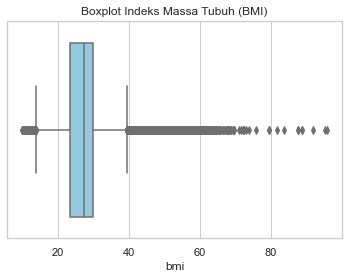

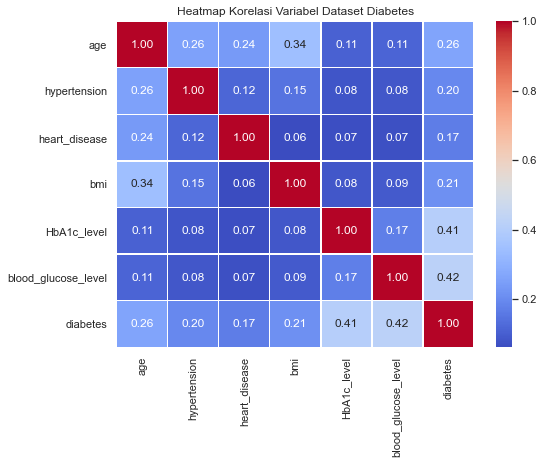

In [4]:
# Trissa Nurul Suci 202431050
# d. Visualisasi Boxplot untuk mendeteksi outlier pada kolom bmi
plt.figure(figsize=(6, 4))
sns.boxplot(x=df["bmi"], color="skyblue")
plt.title("Boxplot Indeks Massa Tubuh (BMI)")
plt.show()

# e. Heatmap Korelasi antar variabel numerik
plt.figure(figsize=(8, 6))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Heatmap Korelasi Variabel Dataset Diabetes")
plt.show()

## Pemodelan Regresi Linear

In [5]:
# Trissa Nurul Suci 202431050
# f. Pemodelan Regresi Linear (Memprediksi HbA1c_level berdasarkan age dan bmi)
X_reg = df[['age', 'bmi']]
y_reg = df['HbA1c_level']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

model_lr = LinearRegression()
model_lr.fit(X_train_r, y_train_r)
y_pred_r = model_lr.predict(X_test_r)

print("Koefisien Regresi (m):", model_lr.coef_)
print("Intercept (c):", model_lr.intercept_)
print("MSE:", mean_squared_error(y_test_r, y_pred_r))
print("RMSE:", np.sqrt(mean_squared_error(y_test_r, y_pred_r)))
print("R^2 Score:", r2_score(y_test_r, y_pred_r))

Koefisien Regresi (m): [0.00419907 0.00875993]
Intercept (c): 5.117966354157395
MSE: 1.1373503434442571
RMSE: 1.066466288001762
R^2 Score: 0.013200198910828465


## Klasifikasi Menggunakan Decision Tree

Accuracy Score: 0.9473738949557983

Confusion Matrix:
 [[16961   548]
 [  464  1257]]

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.97      0.97     17509
           1       0.70      0.73      0.71      1721

    accuracy                           0.95     19230
   macro avg       0.83      0.85      0.84     19230
weighted avg       0.95      0.95      0.95     19230



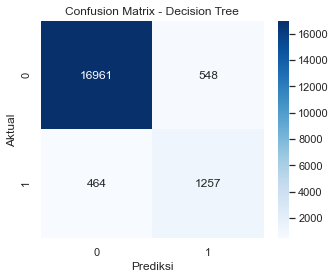

In [6]:
# Trissa Nurul Suci 202431050
# g. Pemodelan Klasifikasi dengan Decision Tree
df_encoded = df.copy()
le = LabelEncoder()
df_encoded['gender'] = le.fit_transform(df_encoded['gender'])
df_encoded['smoking_history'] = le.fit_transform(df_encoded['smoking_history'])

X_class = df_encoded.drop(columns=['diabetes'])
y_class = df_encoded['diabetes']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_class, y_class, test_size=0.2, random_state=42)

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_c, y_train_c)
y_pred_c = dt_model.predict(X_test_c)

print("Accuracy Score:", accuracy_score(y_test_c, y_pred_c))
print("\nConfusion Matrix:\n", confusion_matrix(y_test_c, y_pred_c))
print("\nClassification Report:\n", classification_report(y_test_c, y_pred_c))

# Visualisasi Confusion Matrix
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test_c, y_pred_c), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion Matrix - Decision Tree")
plt.show()